In [6]:
from pathlib import Path
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Path to the CSV made by altimetry_daily_to_csv.py.
# If the notebook is somewhere else, give the full path, e.g.
# CSV = Path("/Users/you/Documents/StormSeaLevel/csv_output/StormSeaLevel_cell.csv")
CSV = Path("/Users/sophiethomas/Desktop/StormSeaLevel/csv_output/StormSeaLevel_cell_Updated.csv")
OUT_PNG = Path("cristobal_sea_level.png")

VAR = "sla"                                      # sea level anomaly (m)
STORM_START, STORM_END = "2020-06-01", "2020-06-07"
CLOSEST = "2020-06-06"                           # closest pass near Progreso (NHC report)
PLOT_START, PLOT_END = "2020-05-01", "2020-07-15"
SEARCH_END = "2020-06-10"                        # allow a few days' lag after the storm
WINDOW_DAYS = 61                                 # running mean that defines "normal" sea level
STORM_COLOR, NEUTRAL = "#2a6fdb", "#8a8f98"

In [7]:
df = pd.read_csv(CSV, parse_dates=["date"])
s = df.set_index("date")[VAR].sort_index() * 100           # m -> cm
s = s[~s.index.duplicated()].asfreq("D")                   # gaps become NaN
print(f"Record: {s.first_valid_index():%Y-%m-%d} to {s.last_valid_index():%Y-%m-%d}")
if s[PLOT_START:PLOT_END].dropna().empty:
    raise ValueError(f"No data between {PLOT_START} and {PLOT_END}")

# Background = 61-day running mean (trend + seasonal cycle), computed WITHOUT the storm days
masked = s.copy()
masked[STORM_START:SEARCH_END] = np.nan
background = masked.rolling(WINDOW_DAYS, center=True, min_periods=WINDOW_DAYS * 2 // 3).mean()
anom = s - background                                       # short-term departure

Record: 1995-01-01 to 2020-12-31


In [8]:
reference = anom.drop(anom[STORM_START:SEARCH_END].index).dropna()   # every other day of the record
p1, p5, p95, p99 = np.percentile(reference, [1, 5, 95, 99])

storm = anom[STORM_START:SEARCH_END].dropna()
peak_day = storm.abs().idxmax()
peak = storm[peak_day]
rank = (reference.abs() < abs(peak)).mean() * 100

print(f"Normal short-term variation: 5-95% = {p5:+.1f} to {p95:+.1f} cm, 1-99% = {p1:+.1f} to {p99:+.1f} cm")
print(f"Largest anomaly {STORM_START} to {SEARCH_END}: {peak:+.1f} cm on {peak_day:%d %b %Y}")
print(f"  larger than {rank:.0f}% of all other days (absolute value)")
if rank >= 99:
    verdict = "stands out clearly from normal variation"
elif rank >= 95:
    verdict = "is unusual but not exceptional"
else:
    verdict = "is within normal day-to-day variation: no detectable storm signal"
print(f"Verdict: the Cristobal signal at this cell {verdict}.")

Normal short-term variation: 5-95% = -6.6 to +6.9 cm, 1-99% = -8.8 to +11.8 cm
Largest anomaly 2020-06-01 to 2020-06-10: +9.0 cm on 10 Jun 2020
  larger than 97% of all other days (absolute value)
Verdict: the Cristobal signal at this cell is unusual but not exceptional.


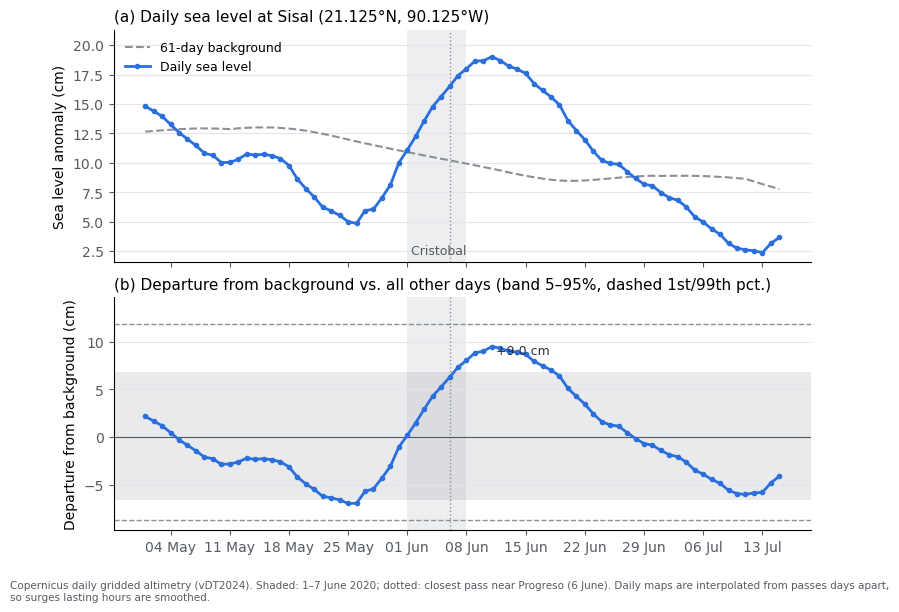

In [9]:
win = slice(PLOT_START, PLOT_END)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True, gridspec_kw=dict(hspace=0.15))

for ax in (ax1, ax2):
    ax.axvspan(pd.Timestamp(STORM_START), pd.Timestamp(STORM_END) + pd.Timedelta(days=1),
               color=NEUTRAL, alpha=0.15, lw=0)
    ax.axvline(pd.Timestamp(CLOSEST), color=NEUTRAL, lw=1, ls=":")
    ax.grid(axis="y", color="#e3e5e8", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors="#555b63")

# (a) sea level and background
ax1.plot(background[win], color=NEUTRAL, lw=1.5, ls="--", label=f"{WINDOW_DAYS}-day background")
ax1.plot(s[win], color=STORM_COLOR, lw=2, marker="o", ms=3, label="Daily sea level")
ax1.set_ylabel("Sea level anomaly (cm)")
ax1.set_title("(a) Daily sea level at Sisal (21.125°N, 90.125°W)", loc="left", fontsize=11)
ax1.legend(frameon=False, loc="upper left", fontsize=9)
ax1.text(pd.Timestamp(STORM_START), 0.02, " Cristobal", transform=ax1.get_xaxis_transform(),
         va="bottom", fontsize=9, color="#555b63")

# (b) departure from background vs. the rest of the record
ax2.axhspan(p5, p95, color=NEUTRAL, alpha=0.18, lw=0)
for p in (p1, p99):
    ax2.axhline(p, color=NEUTRAL, lw=1, ls="--")
ax2.axhline(0, color="#555b63", lw=0.8)
ax2.plot(anom[win], color=STORM_COLOR, lw=2, marker="o", ms=3)
ax2.set_ylabel("Departure from background (cm)")
ax2.set_title("(b) Departure from background vs. all other days (band 5–95%, dashed 1st/99th pct.)",
              loc="left", fontsize=11)
ax2.annotate(f"{peak:+.1f} cm", (peak_day, peak), xytext=(9, 0), textcoords="offset points",
             ha="left", va="center", fontsize=9, color="#2b2f36")

for ax in (ax1, ax2):                                       # headroom above the peak
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo, hi + 0.08 * (hi - lo))

ax2.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.text(0.01, 0.005,
         "Copernicus daily gridded altimetry (vDT2024). Shaded: 1–7 June 2020; dotted: closest pass "
         "near Progreso (6 June). Daily maps are interpolated from passes days apart, so surges "
         "lasting hours are smoothed.", fontsize=7.5, color="#555b63", wrap=True)
fig.savefig(OUT_PNG, dpi=200, bbox_inches="tight")
plt.show()

In [10]:
def storm_sea_level(name, storm_start, storm_end, closest, closest_label, lag_days=3, pad_days=30):
    """Short-term sea level anomaly at Sisal around one storm, compared with all other days."""
    search_end = pd.Timestamp(storm_end) + pd.Timedelta(days=lag_days)
    plot_start = pd.Timestamp(storm_start) - pd.Timedelta(days=pad_days)
    plot_end = pd.Timestamp(storm_end) + pd.Timedelta(days=pad_days)

    have = s[plot_start:plot_end].notna().sum()
    if have < 0.8 * len(pd.date_range(plot_start, plot_end)):
        print(f"{name}: only {have} days of data between {plot_start:%Y-%m-%d} and {plot_end:%Y-%m-%d}. "
              f"Download that period first (the CSV covers "
              f"{', '.join(str(y) for y in sorted(s.dropna().index.year.unique()))}).")
        return

    masked = s.copy()
    masked[storm_start:search_end] = np.nan                     # keep the storm out of "normal"
    background = masked.rolling(WINDOW_DAYS, center=True, min_periods=WINDOW_DAYS * 2 // 3).mean()
    anom = s - background

    reference = anom.drop(anom[storm_start:search_end].index).dropna()
    p1, p5, p95, p99 = np.percentile(reference, [1, 5, 95, 99])
    storm = anom[storm_start:search_end].dropna()
    peak_day = storm.abs().idxmax()
    peak = storm[peak_day]
    rank = (reference.abs() < abs(peak)).mean() * 100

    print(f"{name}: compared with {len(reference):,} other days")
    print(f"  normal variation: 5-95% = {p5:+.1f} to {p95:+.1f} cm, 1-99% = {p1:+.1f} to {p99:+.1f} cm")
    print(f"  largest anomaly {storm_start} to {search_end:%Y-%m-%d}: {peak:+.1f} cm on {peak_day:%d %b %Y},"
          f" larger than {rank:.0f}% of all other days")
    verdict = ("stands out clearly from normal variation" if rank >= 99 else
               "is unusual but not exceptional" if rank >= 95 else
               "is within normal day-to-day variation: no detectable storm signal")
    print(f"  verdict: the {name} signal at this cell {verdict}.")

    win = slice(plot_start, plot_end)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True, gridspec_kw=dict(hspace=0.15))
    for ax in (ax1, ax2):
        ax.axvspan(pd.Timestamp(storm_start), pd.Timestamp(storm_end) + pd.Timedelta(days=1),
                   color=NEUTRAL, alpha=0.15, lw=0)
        ax.axvline(pd.Timestamp(closest), color=NEUTRAL, lw=1, ls=":")
        ax.grid(axis="y", color="#e3e5e8", lw=0.8)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(colors="#555b63")

    ax1.plot(background[win], color=NEUTRAL, lw=1.5, ls="--", label=f"{WINDOW_DAYS}-day background")
    ax1.plot(s[win], color=STORM_COLOR, lw=2, marker="o", ms=3, label="Daily sea level")
    ax1.set_ylabel("Sea level anomaly (cm)")
    ax1.set_title("(a) Daily sea level at Sisal (21.125°N, 90.125°W)", loc="left", fontsize=11)
    ax1.legend(frameon=False, loc="upper left", fontsize=9)
    ax1.text(pd.Timestamp(storm_start), 0.02, f" {name}", transform=ax1.get_xaxis_transform(),
             va="bottom", fontsize=9, color="#555b63")

    ax2.axhspan(p5, p95, color=NEUTRAL, alpha=0.18, lw=0)
    for p in (p1, p99):
        ax2.axhline(p, color=NEUTRAL, lw=1, ls="--")
    ax2.axhline(0, color="#555b63", lw=0.8)
    ax2.plot(anom[win], color=STORM_COLOR, lw=2, marker="o", ms=3)
    ax2.set_ylabel("Departure from background (cm)")
    ax2.set_title("(b) Departure from background vs. all other days (band 5–95%, dashed 1st/99th pct.)",
                  loc="left", fontsize=11)
    ax2.annotate(f"{peak:+.1f} cm", (peak_day, peak), xytext=(9, 0), textcoords="offset points",
                 ha="left", va="center", fontsize=9, color="#2b2f36")
    for ax in (ax1, ax2):
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi + 0.08 * (hi - lo))

    ax2.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    fig.text(0.01, 0.005,
             f"Copernicus daily gridded altimetry (vDT2024). Shaded: {name} period; dotted: {closest_label}. "
             "Daily maps are interpolated from passes days apart, so surges lasting hours are smoothed.",
             fontsize=7.5, color="#555b63", wrap=True)
    fig.savefig(f"{name.lower()}_sea_level.png", dpi=200, bbox_inches="tight")
    plt.show()

Isidore: compared with 1,033 other days
  normal variation: 5-95% = -6.6 to +6.8 cm, 1-99% = -8.8 to +11.8 cm
  largest anomaly 2002-09-20 to 2002-09-28: +14.3 cm on 28 Sep 2002, larger than 100% of all other days
  verdict: the Isidore signal at this cell stands out clearly from normal variation.


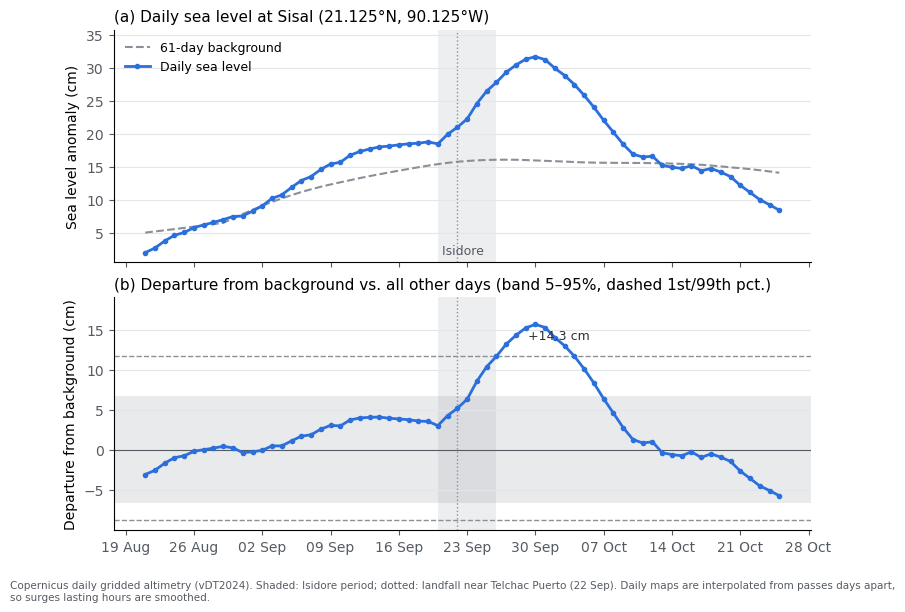

In [11]:
storm_sea_level("Isidore", "2002-09-20", "2002-09-25", "2002-09-22",
                "landfall near Telchac Puerto (22 Sep)")

Cristobal: compared with 1,032 other days
  normal variation: 5-95% = -6.6 to +6.9 cm, 1-99% = -8.8 to +11.8 cm
  largest anomaly 2020-06-01 to 2020-06-10: +9.0 cm on 10 Jun 2020, larger than 97% of all other days
  verdict: the Cristobal signal at this cell is unusual but not exceptional.


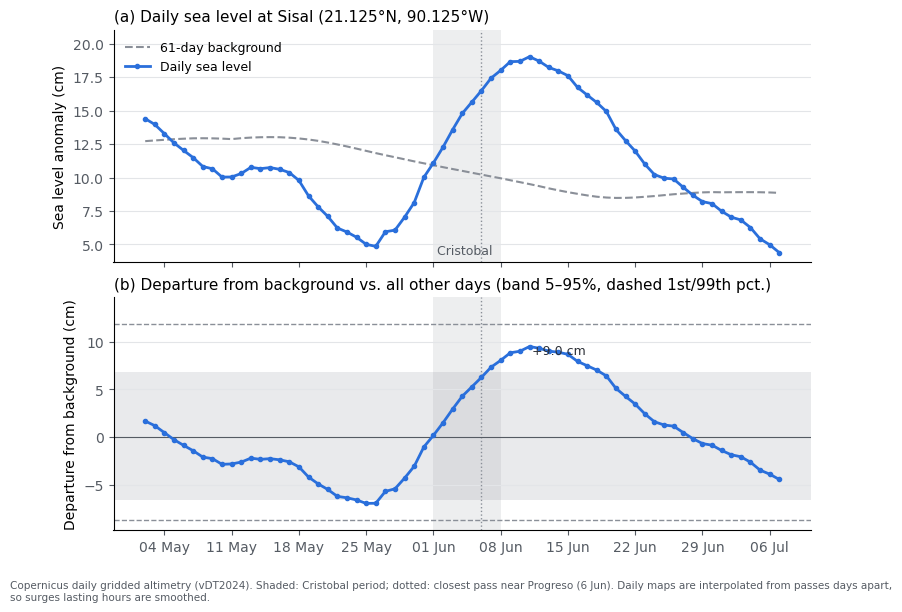

In [12]:
storm_sea_level("Cristobal", "2020-06-01", "2020-06-07", "2020-06-06",
                "closest pass near Progreso (6 Jun)")

Opal: compared with 1,032 other days
  normal variation: 5-95% = -6.7 to +6.9 cm, 1-99% = -8.8 to +12.0 cm
  largest anomaly 1995-09-27 to 1995-10-06: +7.8 cm on 03 Oct 1995, larger than 94% of all other days
  verdict: the Opal signal at this cell is within normal day-to-day variation: no detectable storm signal.


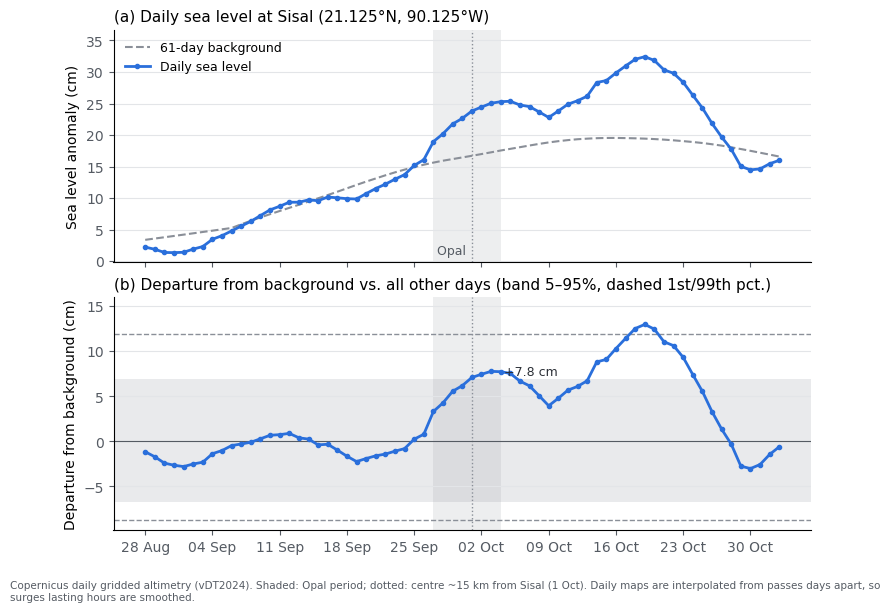

In [13]:
storm_sea_level("Opal", "1995-09-27", "1995-10-03", "1995-10-01",
                "centre ~15 km from Sisal (1 Oct)")